In [1]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack

from beeps import *

Welcome to JupyROOT 6.26/08


# Set config

In [2]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em18"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230301_18'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230301_18/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]

DUMP_PKL = True
DRAW_SR = True
RUN_SIDEBAND_MET = True
RUN_SIDEBAND_MASS = True
RUN_SIDEBAND_PT = True
DUMP_SIDEBAND_MET_PKL = True
DUMP_SIDEBAND_MASS_PKL = True
DUMP_SIDEBAND_PT_PKL = True
RUN_BTAG = False
EXPORT_VARIABLE = False

# # for dev
# ERA="em18"
# DATE = '20230422_18'
# INPUTDIR = "/eos/user/h/hkwon/Run2/"+DATE+"/em/"


# Get input

In [3]:
lumi_all={
    "ee16pre":19520,
    "ee16post":16810,
    "ee17":41480,
    "ee18":59830,
    "mm16pre":19520,
    "mm16post":16810,
    "mm17":41480,
    "mm18":59830,    
#     "mm18":14000,    
    "em16pre":19520,
    "em16post":16810,
    "em17":41480,
    "em18":59830     
}

data_evts = {
    "ee16pre":652566543,
    "ee16post":287977113,
    "ee17":460041183,
    "ee18":1326465857,
    "mm16pre":458655573,
    "mm16post":327037312,
    "mm17":739073837,
#     "mm18":944842550,  #949352777 
    "mm18":949352777,  #949352777 
    "em16pre":1111222116,
    "em16post":615014425,
    "em17":1199115020,
#     "em18":2271308407   #2281001366  
    "em18":2281001366   #2281001366  
}

lumi=lumi_all[ERA]
print(ERA, lumi)

channel = ERA.replace("16pre", "")
channel = channel.replace("16post", "")
channel = channel.replace("17", "")
channel = channel.replace("18", "")

def get_df(root_file_name, unneccesary_columns):
    f = uproot.open(root_file_name)
    df = uproot.open(root_file_name)["Events_"+channel].arrays(library="pd")
    df_met_u = uproot.open(root_file_name)["Events_"+channel+"_met_u"].arrays(library="pd")
    df_met_d = uproot.open(root_file_name)["Events_"+channel+"_met_d"].arrays(library="pd")    
#     df_scale_u = uproot.open(root_file_name)["Events_"+channel+"_scale_u"].arrays(library="pd")
#     df_scale_d = uproot.open(root_file_name)["Events_"+channel+"_scale_d"].arrays(library="pd")
    info = uproot.open(root_file_name)["Info_"+channel].arrays(library="pd")
#     return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1), df_scale_u.drop(unneccesary_columns, axis=1), df_scale_d.drop(unneccesary_columns, axis=1)
    return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1)

unneccesary_columns = []
dic_input = {
    "ee16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/ee/",
    "mm16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/mm/",
    "em16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/em/",
    "ee16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/ee/",
    "mm16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/mm/",
    "em16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/em/",
    "ee17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/ee/",
    "mm17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/mm/",
    "em17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/em/",
    "ee18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/ee/",
    "mm18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/mm/",    
    "em18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/em/"        
#     "em18": "/eos/user/h/hkwon/Run2/20221120_18/em/"        
}
# input_dir = dic_input[ERA]
input_dir = INPUTDIR
f = []
for (dirpath, dirnames, filenames) in os.walk(input_dir):
    f.extend(filenames)
    break

dic_tup={}
for file in tqdm(f):
    # file naming: flatNtuple_Preselect_WZ1.root, flatNtuple_Preselect_Zp-3700_CH-1345.root
    if not "flatNtuple" in file:
        continue
#     if channel=="mm" and (fnmatch.fnmatch(file, '*E*Run*') or fnmatch.fnmatch(file, '*M*RunB*') or fnmatch.fnmatch(file, '*M*RunC*') or fnmatch.fnmatch(file, '*M*RunD*')): #temp
    if channel=="mm" and fnmatch.fnmatch(file, '*E*Run*'): #temp
        continue
    if channel=="ee" and fnmatch.fnmatch(file, '*M*Run*'):
        continue
#     if channel=="em" and fnmatch.fnmatch(file, '*E*Run*'):
#         continue  

    if "Zp" in file:
        sample=file.split('_')[2]+"_"+file.split('_')[3]
    else:
        sample=file.split('_')[2]
    sample=sample.rstrip('.root')
    try:
        print(sample)
        dic_tup[sample]=get_df(input_dir+file, unneccesary_columns)   
    except:
        print(sample)
        beep()        
        if "Run" in sample: # check file corrupt
            raise    
# dic_tup

em18 59830


  0%|          | 0/264 [00:00<?, ?it/s]

DY0


  0%|          | 1/264 [00:00<01:42,  2.57it/s]

DY1


...

 99%|█████████▉| 262/264 [01:59<00:01,  1.80it/s]

Zp-4100_CH-595


100%|█████████▉| 263/264 [02:00<00:00,  1.72it/s]

Zp-4100_CH-845


100%|██████████| 264/264 [02:00<00:00,  2.19it/s]


In [4]:
beep_ok()

In [5]:
# for key in dic_tup:
#     print(key)

In [6]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0.00031, 'Zp-3700_CH-845': 0.00031, 'Zp-3700_CH-1095': 0.00031, 'Zp-3700_CH

In [7]:
Data_concat, TT_concat, TTSemi_concat, TTZ_concat, DY_concat, top_concat, antitop_concat, WW_concat, WZ_concat, ZZ_concat = ([] for i in range(10))
Data_concat_met_u, TT_concat_met_u, TTSemi_concat_met_u, TTZ_concat_met_u, DY_concat_met_u, top_concat_met_u, antitop_concat_met_u, WW_concat_met_u, WZ_concat_met_u, ZZ_concat_met_u = ([] for i in range(10))
Data_concat_met_d, TT_concat_met_d, TTSemi_concat_met_d, TTZ_concat_met_d, DY_concat_met_d, top_concat_met_d, antitop_concat_met_d, WW_concat_met_d, WZ_concat_met_d, ZZ_concat_met_d = ([] for i in range(10))
Data_concat_scale_u, TT_concat_scale_u, TTSemi_concat_scale_u, TTZ_concat_scale_u, DY_concat_scale_u, top_concat_scale_u, antitop_concat_scale_u, WW_concat_scale_u, WZ_concat_scale_u, ZZ_concat_scale_u = ([] for i in range(10))
Data_concat_scale_d, TT_concat_scale_d, TTSemi_concat_scale_d, TTZ_concat_scale_d, DY_concat_scale_d, top_concat_scale_d, antitop_concat_scale_d, WW_concat_scale_d, WZ_concat_scale_d, ZZ_concat_scale_d = ([] for i in range(10))

Data_nevts, TT_nevts, TTSemi_nevts, TTZ_nevts, DY_nevts, top_nevts, antitop_nevts, WW_nevts, WZ_nevts, ZZ_nevts = ([] for i in range(10))

merged_dic_df={}
for key in dic_tup:
    if fnmatch.fnmatch(key, 'DY?') or fnmatch.fnmatch(key, 'DY??'):
        print(key)
        DY_concat.append(dic_tup[key][1])
        DY_concat_met_u.append(dic_tup[key][2])
        DY_concat_met_d.append(dic_tup[key][3])        
#         DY_concat_scale_u.append(dic_tup[key][4])
#         DY_concat_scale_d.append(dic_tup[key][5])
        DY_nevts.append(dic_tup[key][0])
        print(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TT?') or fnmatch.fnmatch(key, 'TT??'):
        TT_concat.append(dic_tup[key][1])
        TT_concat_met_u.append(dic_tup[key][2])
        TT_concat_met_d.append(dic_tup[key][3])
#         TT_concat_scale_u.append(dic_tup[key][4])
#         TT_concat_scale_d.append(dic_tup[key][5])
        TT_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTSemi*'):
        TTSemi_concat.append(dic_tup[key][1])
        TTSemi_concat_met_u.append(dic_tup[key][2])
        TTSemi_concat_met_d.append(dic_tup[key][3])
#         TTSemi_concat_scale_u.append(dic_tup[key][4])
#         TTSemi_concat_scale_d.append(dic_tup[key][5])
        TTSemi_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTZ*'):
        TTZ_concat.append(dic_tup[key][1])
        TTZ_concat_met_u.append(dic_tup[key][2])
        TTZ_concat_met_d.append(dic_tup[key][3])
#         TTZ_concat_scale_u.append(dic_tup[key][4])
#         TTZ_concat_scale_d.append(dic_tup[key][5])
        TTZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TW?'):
        top_concat.append(dic_tup[key][1])
        top_concat_met_u.append(dic_tup[key][2])
        top_concat_met_d.append(dic_tup[key][3])
#         top_concat_scale_u.append(dic_tup[key][4])
#         top_concat_scale_d.append(dic_tup[key][5])
        top_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TWa?'):
        antitop_concat.append(dic_tup[key][1])
        antitop_concat_met_u.append(dic_tup[key][2])
        antitop_concat_met_d.append(dic_tup[key][3])
#         antitop_concat_scale_u.append(dic_tup[key][4])
#         antitop_concat_scale_d.append(dic_tup[key][5])
        antitop_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'WW*'):
        WW_concat.append(dic_tup[key][1])
        WW_concat_met_u.append(dic_tup[key][2])
        WW_concat_met_d.append(dic_tup[key][3])
#         WW_concat_scale_u.append(dic_tup[key][4])
#         WW_concat_scale_d.append(dic_tup[key][5])
        WW_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'WZ*'):
        WZ_concat.append(dic_tup[key][1])
        WZ_concat_met_u.append(dic_tup[key][2])
        WZ_concat_met_d.append(dic_tup[key][3])
#         WZ_concat_scale_u.append(dic_tup[key][4])
#         WZ_concat_scale_d.append(dic_tup[key][5])
        WZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'ZZ*'):
        ZZ_concat.append(dic_tup[key][1])
        ZZ_concat_met_u.append(dic_tup[key][2])
        ZZ_concat_met_d.append(dic_tup[key][3])
#         ZZ_concat_scale_u.append(dic_tup[key][4])
#         ZZ_concat_scale_d.append(dic_tup[key][5])
        ZZ_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, '*Run*'):
        Data_concat.append(dic_tup[key][1])
        Data_concat_met_u.append(dic_tup[key][2])
        Data_concat_met_d.append(dic_tup[key][3])
#         Data_concat_scale_u.append(dic_tup[key][4])
#         Data_concat_scale_d.append(dic_tup[key][5])
        Data_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'Zp*'): 
        merged_dic_df[key]=dic_tup[key]
    if fnmatch.fnmatch(key, 'DY*To*'): 
        merged_dic_df[key]=dic_tup[key]
        print("high", key)

DY0
3081301
DY1
5137820
DY10
7717518
high DY1000To15000
DY11
10415848
DY12
6149058
DY13
5039444
DY14
7189686
DY15
9197157
high DY1500To20000
DY16
5888770
DY17
3749225
DY18
5011966
DY19
4754430
DY2
6466029
DY20
2963693
high DY2000To30000
DY3
6850646
DY4
9022257
DY5
6110199
high DY500To7000
DY6
6402318
DY7
5567140
high DY700To8000
DY8
5517922
high DY800To10000
DY9
9332911


In [8]:
# free memory 
dic_tup.clear()

In [9]:
totalinput = """
######################################################
####   Total input number of events (sumweight)   ####
######################################################
"""

print(totalinput)
if TT_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d)
    tmp = "TT: "+str(sum(TT_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TTSemi_concat:
#     merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d), pd.concat(TTSemi_concat_scale_u), pd.concat(TTSemi_concat_scale_d)
    merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d)
    tmp = "TTSemi: "+str(sum(TTSemi_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTZ_concat:
#     merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d), pd.concat(TTZ_concat_scale_u), pd.concat(TTZ_concat_scale_d)
    merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d)
    tmp = "TTZ: "+str(sum(TTZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if DY_concat:
#     merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d), pd.concat(DY_concat_scale_u), pd.concat(DY_concat_scale_d)
    merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d)
    tmp = "DY: "+str(sum(DY_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if top_concat:
    df=pd.concat(top_concat)
#     merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d), pd.concat(top_concat_scale_u), pd.concat(top_concat_scale_d)
    merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d)
    tmp = "top: "+str(sum(top_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if antitop_concat:
    df=pd.concat(antitop_concat)
#     merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d), pd.concat(antitop_concat_scale_u), pd.concat(antitop_concat_scale_d)
    merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d)
    tmp = "antitop: "+str(sum(antitop_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if ZZ_concat:
    df=pd.concat(ZZ_concat)
#     merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d), pd.concat(ZZ_concat_scale_u), pd.concat(ZZ_concat_scale_d)
    merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d)
    tmp = "ZZ: "+str(sum(ZZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WZ_concat:
    df=pd.concat(WZ_concat)
#     merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d), pd.concat(WZ_concat_scale_u), pd.concat(WZ_concat_scale_d)
    merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d)
    tmp = "WZ: "+str(sum(WZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WW_concat:
    df=pd.concat(WW_concat)
#     merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d), pd.concat(WW_concat_scale_u), pd.concat(WW_concat_scale_d)
    merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d)
    tmp = "WW: "+str(sum(WW_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if Data_concat:
#     merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d), pd.concat(Data_concat_scale_u), pd.concat(Data_concat_scale_d)
    merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d)
    tmp = "Data: "+str(sum(Data_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
# merged_dic_df["Zp-2500"]=dic_tup["Zp-2500"][0], dic_tup["Zp-2500"][1] 



######################################################
####   Total input number of events (sumweight)   ####
######################################################

TT: 153500682
TTSemi: 472557630
TTZ: 9651834
DY: 131565338
top: 7762626
antitop: 7748690
ZZ: 48848724
WZ: 24303029
WW: 8607614
Data: 2281001366


In [10]:
os.system("mkdir -p "+DATE+"/Presel/"+ERA)
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'w') as f:
    f.write(totalinput)

In [11]:
try:
   if data_evts[ERA]!=sum(Data_nevts):
       raise ValueError('Data events missing!')
except (ValueError, IndexError):
   beep()
   print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts)) 
   raise

In [12]:
# # temp!!
for key in merged_dic_df:
    df = merged_dic_df[key][1]
    df_met_u = merged_dic_df[key][2]
    df_met_d = merged_dic_df[key][3]    
#     df_scale_u = merged_dic_df[key][4]
#     df_scale_d = merged_dic_df[key][5]
#     print(df[df.isin([np.inf, -np.inf]).any(1)])
    if df.isnull().values.any():
        print("Warning, nan in",key)
        i = df[df.isin([np.nan, np.inf, -np.inf]).any(1)].index
        print(i)
        df_new = df.drop(i)
        df_met_u_new = df_met_u.drop(i)
        df_met_d_new = df_met_d.drop(i)
#         print(df_new.isnull().values.any())
        #workaround for tuple assignment
#         merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new, df_scale_u, df_scale_d
        merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new
        


In [13]:
sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre', 'trigSF_pre']
eventweights = """
####################################################
####       event weights (normalization)        ####
####################################################
"""

def get_dic_with_weight(merged_dic_df):
    dic_df={}
    dic_df_met_u={}
    dic_df_met_d={}
    dic_df_scale_u={}
    dic_df_scale_d={}
    for key, vs in merged_dic_df.items():
        print(key)
        if "16pre" in ERA and key=="Zp-2500_CH-595": # signal sample missing
            continue    
        if "Data" in key:
            norm=1
        else:
            if fnmatch.fnmatch(key, '*DY*To*'):
                key = key[:len(key)-1]
            norm=lumi*dic_xsec[key]/vs[0]
        print(key, ":", norm)
        global eventweights
        eventweights+=key+":"+str(norm)+"\n"
#         print(eventweights)
        dic_df[key]=vs[1]
        dic_df_met_u[key] = vs[2]
        dic_df_met_d[key]=vs[3]
#         dic_df_scale_u[key] = vs[4]
#         dic_df_scale_d[key]=vs[5]
        dic_df[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_u[key]["weightmetUp"] = vs[1]["genweight_pre"]*norm
        dic_df_met_d[key]["weightmetDown"] = vs[1]["genweight_pre"]*norm
#         dic_df_scale_u[key]["weightscaleUp"] = vs[4]["totweight"].copy(deep=True)
#         dic_df_scale_d[key]["weightscaleDown"] =vs[5]["totweight"].copy(deep=True)
        dic_df[key]["wopu"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wol1"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["woeff"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wotop"] = vs[1]["genweight_pre"]*norm       
        dic_df[key]["wobsf"] = vs[1]["genweight_pre"]*norm       
      
        for s in sys:
            if s=="genweight_pre":
                continue
            dic_df[key]["weight"] *= vs[1][s]
            dic_df_met_u[key]["weightmetUp"] *= vs[1][s]
            dic_df_met_d[key]["weightmetDown"] *= vs[1][s]
            # n-1 correction
            if s!="puweight_pre":
                dic_df[key]["wopu"] *= vs[1][s]
            if s!="l1prefiring_pre":
                dic_df[key]["wol1"] *= vs[1][s]
            if s!="effSF_pre":
                dic_df[key]["woeff"] *= vs[1][s]
#             if s!="topSF_pre":
            if not "top" in s:
                dic_df[key]["wotop"] *= vs[1][s]
            if s!="btagSF_pre":
                dic_df[key]["wobsf"] *= vs[1][s]
        #btag    
#         dic_df[key]["btag2"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF2_pre'] 
#         dic_df[key]["btagSF"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF_pre']
            
        # up, down    
        for s1 in sys:
            #if "top" in s1 or "eff" in s1:
            if "btag" in s1:
                continue
            s_u = s1.replace("_", "_u_")
            s_d = s1.replace("_", "_d_")
            if s1=="genweight_pre":
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_u])
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_d])
            else:
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_u]
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_d]             
#     return dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d
    return dic_df, dic_df_met_u, dic_df_met_d

# dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d = get_dic_with_weight(merged_dic_df)
dic_df, dic_df_met_u, dic_df_met_d = get_dic_with_weight(merged_dic_df)


DY1000To15000
DY1000To1500 : 0.009785467982499308
DY1500To20000
DY1500To2000 : 0.0012113801686825314
DY2000To30000
DY2000To3000 : 0.00028492232043809756
DY500To7000
DY500To700 : 0.09659806229684098
DY700To8000
DY700To800 : 0.021584576686126282
DY800To10000
DY800To1000 : 0.01815582501781896
Zp-1700_CH-345
Zp-1700_CH-345 : 0.014052072666666667
Zp-1700_CH-595
Zp-1700_CH-595 : 0.014052072666666667
Zp-1700_CH-845
Zp-1700_CH-845 : 0.014052072666666667
Zp-2100_CH-345
Zp-2100_CH-345 : 0.004778422666666666
Zp-2100_CH-595
Zp-2100_CH-595 : 0.004778422666666666
Zp-2100_CH-845
Zp-2100_CH-845 : 0.004778422666666666
Zp-2500_CH-345
Zp-2500_CH-345 : 0.0017892019047619047
Zp-2500_CH-595
Zp-2500_CH-595 : 0.0017534178666666666
Zp-2500_CH-845
Zp-2500_CH-845 : 0.0017534178666666666
Zp-2900_CH-1095
Zp-2900_CH-1095 : 0.0007051962666666667
Zp-2900_CH-1345
Zp-2900_CH-1345 : 0.0007051962666666667
Zp-2900_CH-345
Zp-2900_CH-345 : 0.0007051962666666667
Zp-2900_CH-595
Zp-2900_CH-595 : 0.0007051962666666667
Zp-2900_C

In [14]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(eventweights)

# Preselection

In [15]:
weihtedevents = """
#############################################################
####   unweighted (weighted) #events after preselection  ####
#############################################################
"""
dic_df_raw={}
dic_df_met_u_tmp = {}
dic_df_met_d_tmp = {}
# dic_df_scale_u_tmp = {}
# dic_df_scale_d_tmp = {}
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and roccoMET_pre>100"
query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>500 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and MET_pre>100"
# query_str="pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
# query_str="mass_pre>60"


for key in dic_df:  
    dic_df_raw[key]=dic_df[key].query(query_str)
    dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
    dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)    
#     dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#     dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str)
    unweighted_nevt = dic_df_raw[key].shape[0]
    print(key, ":", unweighted_nevt, "(", sum(dic_df_raw[key]["weight"]), ")")
    print(key, "(met_u) :", dic_df_met_u_tmp[key].shape[0])
    print(key, "(met_d) :", dic_df_met_d_tmp[key].shape[0])
#     print(key, "(scale_u) :", dic_df_scale_u_tmp[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d_tmp[key].shape[0])    
#     print(key, "(scale_u) :", dic_df_scale_u[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d[key].shape[0])
    weihtedevents+=key+":"+str(unweighted_nevt)+"("+str(sum(dic_df_raw[key]["weight"]))+")\n"
#     print(key, ":", unweighted_nevt, "(", unweighted_nevt*lumi*dic_xsec[key]/merged_dic_df[key][0], ")")

nested_dic_df={}
nested_dic_df["raw"]=dic_df_raw
nested_dic_df["met_u"]=dic_df_met_u_tmp
nested_dic_df["met_d"]=dic_df_met_d_tmp
# nested_dic_df["scale_u"]=dic_df_scale_u_tmp
# nested_dic_df["scale_d"]=dic_df_scale_d_tmp

DY1000To1500 : 1071 ( 5.828989417757839 )
DY1000To1500 (met_u) : 1084
DY1000To1500 (met_d) : 1063
DY1500To2000 : 1662 ( 1.0939339009928517 )
DY1500To2000 (met_u) : 1665
DY1500To2000 (met_d) : 1657
DY2000To3000 : 1805 ( 0.27413624979089946 )
DY2000To3000 (met_u) : 1809
DY2000To3000 (met_d) : 1800
DY500To700 : 426 ( 20.493300519883633 )
DY500To700 (met_u) : 431
DY500To700 (met_d) : 408
DY700To800 : 596 ( 6.599861381575465 )
DY700To800 (met_u) : 605
DY700To800 (met_d) : 589
DY800To1000 : 753 ( 7.379266764968634 )
DY800To1000 (met_u) : 758
DY800To1000 (met_d) : 750
Zp-1700_CH-345 : 24140 ( 322.1596139485067 )
Zp-1700_CH-345 (met_u) : 24206
Zp-1700_CH-345 (met_d) : 24047
Zp-1700_CH-595 : 29564 ( 393.2923337531745 )
Zp-1700_CH-595 (met_u) : 29603
Zp-1700_CH-595 (met_d) : 29514
Zp-1700_CH-845 : 32560 ( 432.0009059826348 )
Zp-1700_CH-845 (met_u) : 32578
Zp-1700_CH-845 (met_d) : 32516
Zp-2100_CH-345 : 28151 ( 128.46765108566103 )
Zp-2100_CH-345 (met_u) : 28215
Zp-2100_CH-345 (met_d) : 28069
Zp-

In [16]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(weihtedevents)

In [17]:
if DUMP_PKL:
    os.system("mkdir -p "+DATE+"/Presel/"+ERA)
    print("Dump pickle")
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

Dump pickle


# Draw

In [18]:
# draw
# get plot configuration
dic_variable={
    "PuppiMET_pre": [14, 0, 660, "Puppi p_{T}^{miss} [GeV]"],    
#     "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
    "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#     "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
#     "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
#     "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
#     "U_pre": [14, 0, 660, "U [GeV]"],
#     "JZB_pre": [14, 80, 660, "JZB"],
#     "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#     "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#     "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#     "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
# #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
# #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
# #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#     "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
#     "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# #     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# #     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
# #     "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
#     "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
#     "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF_pre": [100, 0, 10, "SV dxy"],     
}
if "em" in ERA:
    dic_variable["pt_el_pre"] = [15, 20,  660, "p_{T}(e) [GeV]"]
    dic_variable["pt_mu_pre"] = [15, 20,  660, "p_{T}(#mu) [GeV]"]
print(dic_variable)
list_variables = [(key, dic_variable[key]) for key in dic_variable]
print(list_variables)

{'PuppiMET_pre': [14, 0, 660, 'Puppi p_{T}^{miss} [GeV]'], 'mass_pre': [22, 100, 1000, 'M_{ll} [GeV]'], 'pt_lead_pre': [15, 80, 660, 'p_{T}(l_{lead}) [GeV]'], 'pt_trail_pre': [15, 40, 520, 'p_{T}(l_{trail}) [GeV]'], 'pt_el_pre': [15, 20, 660, 'p_{T}(e) [GeV]'], 'pt_mu_pre': [15, 20, 660, 'p_{T}(#mu) [GeV]']}
[('PuppiMET_pre', [14, 0, 660, 'Puppi p_{T}^{miss} [GeV]']), ('mass_pre', [22, 100, 1000, 'M_{ll} [GeV]']), ('pt_lead_pre', [15, 80, 660, 'p_{T}(l_{lead}) [GeV]']), ('pt_trail_pre', [15, 40, 520, 'p_{T}(l_{trail}) [GeV]']), ('pt_el_pre', [15, 20, 660, 'p_{T}(e) [GeV]']), ('pt_mu_pre', [15, 20, 660, 'p_{T}(#mu) [GeV]'])]


In [19]:
import math
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met", "scale"]
sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "met"]
# sys_list = ["l1prefiring"]

def draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, r, region):
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/norm_"+query_str)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        if "met" in s or "scale" in s: # fill later
            continue
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
    if "el_pre" not in variable and "mu_pre" not in variable: #temp
        # shape sys
        hist=HistStack(dic_nested_shape_sys['met_u'], variable, 'weightmetUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_d'], variable, 'weightmetDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metDown'] = np.array(sysUp) - np.array(bkg_norm)

#     hist=HistStack(dic_nested_shape_sys['scale_u'], variable, 'weightscaleUp', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleUp'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_d'], variable, 'weightscaleDown', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleDown'] = np.array(sysUp) - np.array(bkg_norm) 
    else:
#         sys_list = ["puweight", "l1prefiring", "effSF", "topSF"]
        sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"]
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
#     print(dic_sys)
#     print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr
        
# dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list, 'PuppiMET_pre', [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"])

In [20]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/sys")
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df_raw, nested_dic_df, sys_list, variable, dic_variable[variable], region)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr) 
    threshold = 1
    if region=='SR':
        if not 'PuppiMET' in variable and not 'eta' in variable:
            threshold = 0.3
        
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([2.00850736e+02, 1.82002223e+03, 5.83785118e+02, 1.62643799e+01,
       1.01937673e+01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       1.31549031e-01, 1.09636804e-03, 0.00000000e+00, 4.87040413e-03,
       1.15469289e-01, 1.77345815e-02, 1.59888189e-01]), 'puweightDown': array([2.01951954e+02, 1.89296728e+03, 5.02298899e+02, 2.46812404e+01,
       1.16507371e+01, 1.43351414e-01, 9.34699335e-02, 1.32204475e-01,
       1.93192426e-01, 3.03222399e-04, 6.84992117e-03, 8.37891063e-03,
       1.33725008e-01, 1.66483150e-02, 7.75494658e-02]), 'l1prefiringUp': array([2.73540373e+01, 8.40999410e+01, 2.90261158e+01, 4.88454546e+00,
       9.33902678e-01, 1.84005037e-01, 4.12386614e-02, 9.48325907e-03,
       2.36837643e-03, 7.56396591e-04, 1.92320930e-04, 8.91860320e-05,
       4.10236506e-05, 1.14301648e-05, 7.12336850e-05]), 'l1prefiringDown': array([3.02547854e+01, 9.29202502e+01, 3.20823318e+01, 5.38827393e+00,
       1.03044208e+00, 2.02900466e-01, 4.51252786e-0

       1.27980802e-01, 1.54735039e-01, 2.54932972e-01])}
here {'puweightUp': array([5.24802629e+02, 1.55200377e+03, 4.48974666e+02, 4.81739099e+00,
       2.52668924e-01, 2.76932964e-01, 1.65058851e-01, 2.13541928e-01,
       3.32958126e-01, 4.85265954e-01, 1.36231484e-01, 3.84181138e-04,
       3.80333885e-04, 8.96758869e-03, 3.47538445e-02]), 'puweightDown': array([5.74872759e+02, 1.61717272e+03, 4.17328765e+02, 1.30927825e+01,
       5.88257869e-02, 0.00000000e+00, 4.88520727e-01, 1.95007720e-01,
       1.51208338e-01, 2.02908502e-01, 1.35103477e-01, 4.39370043e-03,
       5.87682044e-03, 2.07519851e-02, 3.94770705e-02]), 'l1prefiringUp': array([3.16600908e+01, 8.41679267e+01, 2.61521868e+01, 4.46037880e+00,
       8.68420948e-01, 1.79596722e-01, 4.40817758e-02, 9.58837491e-03,
       2.77650046e-03, 9.48545993e-04, 2.03304634e-04, 9.09199783e-05,
       1.94696185e-05, 6.94372662e-06, 5.03811285e-05]), 'l1prefiringDown': array([3.49552752e+01, 9.30245932e+01, 2.88665283e+01, 4.9334

       2.05211906e-01, 1.26758507e+00])}
{'puweightUp': array([3.23962711e+03, 4.78124143e+02, 2.46506680e+01, 1.57516408e+01,
       3.01795366e-01, 2.46539174e-01, 3.08201855e-01, 2.88142757e-02,
       1.60651648e+00, 0.00000000e+00, 1.73768139e-01, 1.05166245e-01,
       1.22610100e-01, 7.01825700e-02, 3.35953919e-01]), 'puweightDown': array([3.23897040e+03, 4.61222693e+02, 3.59700453e+01, 1.79260291e+01,
       3.39893433e-01, 1.06121873e+00, 5.65871559e-01, 1.10357415e-01,
       6.67864763e-01, 1.53616205e-02, 2.09311104e-01, 2.06260448e-01,
       1.64234416e-01, 9.38503725e-02, 2.11295172e-01]), 'l1prefiringUp': array([1.34554862e+02, 3.77032454e+01, 9.02715905e+00, 2.20422486e+00,
       5.38265021e-01, 1.45563769e-01, 4.04414514e-02, 1.11707796e-02,
       3.89806853e-03, 1.23529591e-03, 4.04997581e-04, 1.95317550e-04,
       7.83498557e-05, 2.53411141e-05, 2.27753973e-04]), 'l1prefiringDown': array([1.48655471e+02, 4.16913341e+01, 9.97341693e+00, 2.43298360e+00,
       5.94

       4.85974567e-02, 1.07437427e-01, 3.28902453e-02])}
here {'puweightUp': array([2.22188453e+03, 1.05842313e+03, 3.34691381e+01, 3.07387705e+00,
       0.00000000e+00, 0.00000000e+00, 4.56564019e-01, 6.02667329e-02,
       6.08179569e-03, 2.29968298e-04, 1.01669461e-02, 1.50511699e-03,
       4.79535393e-05, 1.36957730e-03, 3.79134279e-04]), 'puweightDown': array([2.41160766e+03, 1.00765410e+03, 3.27743613e+01, 3.87548892e+00,
       5.36704496e-02, 8.55678623e-03, 3.24488056e-01, 6.67982423e-02,
       1.69963429e-02, 4.00744643e-05, 9.82869961e-03, 2.56519401e-03,
       7.88492833e-04, 1.12408804e-03, 4.30089878e-04]), 'l1prefiringUp': array([2.01351772e+02, 4.33475813e+01, 3.85809446e+00, 4.22111923e-01,
       5.84854199e-02, 9.40934343e-03, 1.96099310e-03, 4.49229555e-04,
       8.94524846e-05, 1.83533109e-05, 6.84837650e-06, 1.33467475e-06,
       1.41760930e-06, 2.60796883e-07, 5.37562516e-07]), 'l1prefiringDown': array([2.22553023e+02, 4.78985681e+01, 4.25486392e+00, 4.6236

         0.42257197,   0.77498671])}
here {'puweightUp': array([3.21683144e+02, 4.15109523e+02, 3.69706566e+02, 1.14091950e+02,
       9.30775309e+01, 1.69469770e+01, 4.26961399e+00, 7.75750206e-02,
       1.71646095e+00, 1.69951697e-01, 1.44492647e-02, 6.22031502e-02,
       4.87180491e-01, 2.89921277e-05, 2.16423107e-02, 6.56371873e-03,
       2.02691722e-01, 8.19052836e-03, 3.03841855e-02, 1.10837119e-03,
       4.21541192e-02, 1.25754287e-03]), 'puweightDown': array([3.08399415e+02, 5.06655730e+02, 4.03138623e+02, 1.03846403e+02,
       7.91780838e+01, 1.40347716e+01, 7.15379597e+00, 2.84264812e-01,
       1.94128401e+00, 7.87070084e-01, 0.00000000e+00, 0.00000000e+00,
       1.90903291e-01, 6.67982654e-04, 2.59209135e-02, 1.22475073e-02,
       1.69856840e-01, 6.23171293e-05, 1.69600800e-02, 4.31709682e-03,
       4.88486432e-02, 9.52826904e-04]), 'l1prefiringUp': array([1.33397133e+01, 3.84085413e+01, 2.42569255e+01, 1.06473932e+01,
       4.14189325e+00, 1.66372546e+00, 6.839500

Info in <TCanvas::Print>: pdf file 20230422_18/Presel/em18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_el_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230422_18/Presel/em18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_mu_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230422_18/Presel/em18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_mu_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230422_18/Presel/em18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230422_18/Presel/em18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_el_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230422_18/Presel/em18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 

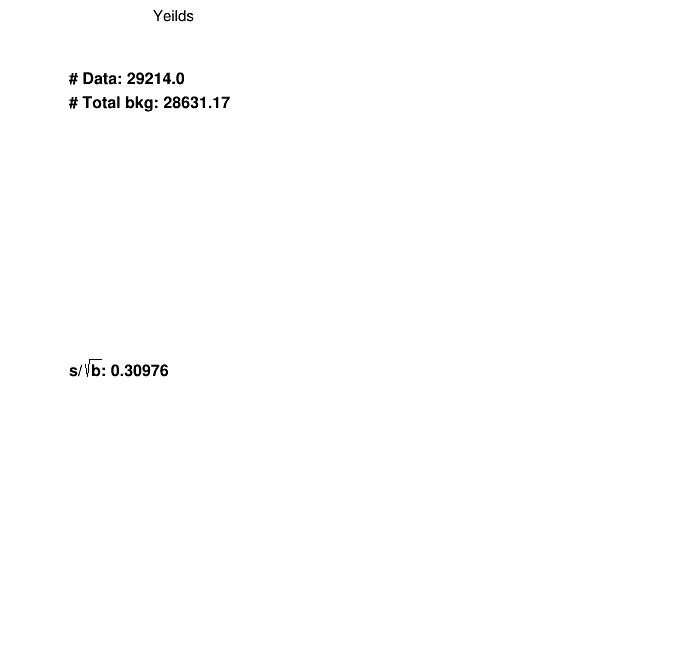

In [21]:
if DRAW_SR:
    region = "SR"

    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)

In [22]:
dic_df_raw["TT"]["trigSF_pre"]

2       0.954826
7       0.986403
11      0.990504
19      0.991238
28      0.967570
          ...   
8568    0.991238
8578    0.986510
8584    0.975867
8586    0.971111
8587    0.968883
Name: trigSF_pre, Length: 850942, dtype: float32

# MET side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 179
DY1500To2000 : 145
DY2000To3000 : 136
DY500To700 : 173
DY700To800 : 161
DY800To1000 : 173
Zp-1700_CH-345 : 3435
Zp-1700_CH-595 : 2654
Zp-1700_CH-845 : 2108
Zp-2100_CH-345 : 3237
Zp-2100_CH-595 : 2606
Zp-2100_CH-845 : 1985
Zp-2500_CH-345 : 2917
Zp-2500_CH-595 : 2389
Zp-2500_CH-845 : 1900
Zp-2900_CH-1095 : 1453
Zp-2900_CH-1345 : 1226
Zp-2900_CH-345 : 2666
Zp-2900_CH-595 : 2274
Zp-2900_CH-845 : 1760
Zp-3300_CH-1095 : 1355
Zp-3300_CH-1345 : 1077
Zp-3300_CH-1595 : 1024
Zp-3300_CH-345 : 2534
Zp-3300_CH-595 : 2073
Zp-3700_CH-1095 : 1246
Zp-3700_CH-1345 : 1092
Zp-3700_CH-1595 : 881
Zp-3700_CH-1845 : 750
Zp-3700_CH-345 : 2285
Zp-3700_CH-595 : 1952
Zp-3700_CH-845 : 1524
Zp-4100_CH-1095 : 1123
Zp-4100_CH-1345 : 1010
Zp-4100_CH-1595 : 832
Zp-4100_CH-1845 : 751
Zp-4100_CH-345 : 2103
Zp-4100_CH-595 : 1795
Zp-4100_CH-845 : 14

       133.16963969,  97.10658159, 101.57177488,  83.70618838])}
{'puweightUp': array([1.35156217e+01, 2.83130160e-01, 7.61058200e+00, 9.87683608e-01,
       6.14931822e-01, 0.00000000e+00, 8.82316508e-01, 7.53676102e-01,
       4.27525723e-01, 1.88692082e-02, 1.17690159e-03, 1.02942789e+00,
       7.28239191e-02, 4.71662887e-02, 9.93384658e-02, 2.23517176e-01,
       3.55869898e-04, 2.20304362e-02, 6.28623389e-02, 1.48664250e-03,
       3.53287904e-03, 0.00000000e+00, 2.90244606e-05, 1.21082494e-04,
       4.32289271e-03, 2.85710183e-04, 1.62916145e-03, 6.07721643e-03,
       1.82659484e-04, 4.25749402e-04, 3.13259020e-03]), 'puweightDown': array([1.72314771e+01, 2.04698962e+00, 1.43749535e+01, 3.59695525e+00,
       0.00000000e+00, 3.14704138e-01, 2.40714444e-01, 8.19994418e-01,
       1.40722110e-02, 5.71456372e-02, 3.19568837e-02, 1.62417765e-01,
       7.90832026e-02, 1.03767692e-02, 9.49482291e-02, 2.21535499e-01,
       0.00000000e+00, 3.65175917e-02, 1.88950172e-02, 7.05630582e

       1.39333934e-02, 2.66603890e-02, 7.47586233e-02])}
{'puweightUp': array([3.30664986e+01, 7.08844180e-01, 6.23517115e+01, 4.45860828e+00,
       7.88094152e-01, 1.72163339e+00, 4.63722743e-01, 3.81736708e-01,
       3.28049386e-02, 1.88689630e-03, 5.14086577e-01, 5.41112725e-02,
       6.34934175e-02, 1.74787846e-03, 5.64754853e-03, 4.47536310e-05,
       6.64105548e-04, 1.83370009e-04, 1.75618402e-03, 9.57319874e-04,
       5.97520345e-03, 5.17842987e-04, 1.61320082e-04, 2.62172144e-05,
       4.33531303e-05, 2.13471046e-04, 7.69059241e-06, 3.80453884e-10,
       8.50830691e-04, 0.00000000e+00]), 'puweightDown': array([4.80919942e+01, 5.19006388e-01, 6.95362880e+01, 1.20952041e+00,
       1.69464502e+00, 1.69188182e+00, 1.18503357e+00, 5.23961857e-01,
       1.70736958e-01, 5.27920639e-03, 2.29815082e-01, 6.54305445e-02,
       4.89355580e-02, 4.59773011e-03, 1.46508379e-03, 4.21777259e-05,
       2.37039632e-03, 1.93663454e-06, 1.90791192e-03, 8.49670243e-04,
       2.94306068e-

       2.13082161e-02, 4.02801543e-02])}
array('f', [8.271026611328125, 0.021984614431858063, 17.251611709594727, 544.6978759765625, 1478.7215576171875, 36.338871002197266, 13640.9599609375, 39.33100128173828, 4.993113994598389])
test


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230422_18/Presel/em18/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230422_18/Presel/em18/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230422_18/Presel/em18/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230422_18/Presel/em18/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_lead_prebreakdo

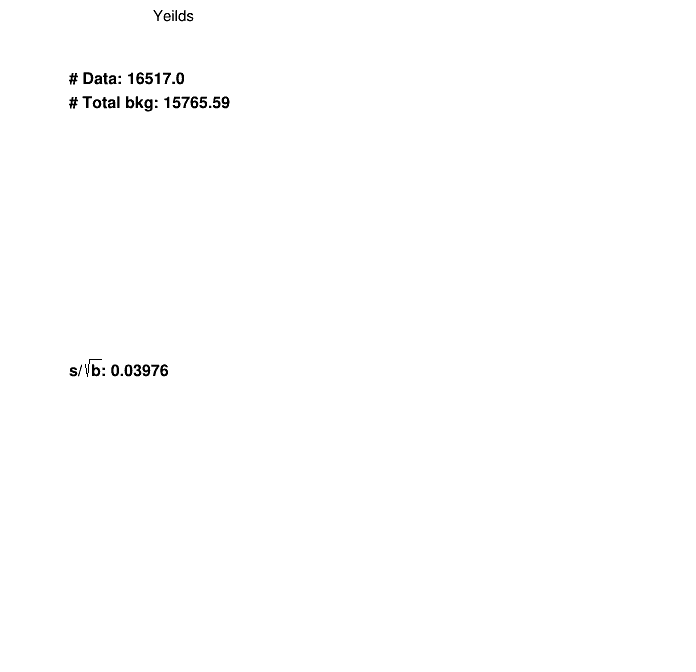

In [23]:
if RUN_SIDEBAND_MET:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "METSB"
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [24]:
if DUMP_SIDEBAND_MET_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_METSB.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# Mass side band

In [25]:
if RUN_SIDEBAND_MASS and not "em" in ERA:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    
    dic_variable={
        "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [1,80, 100, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    }

    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "MASSSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "mass_pre", "weight", 1, 80,  100, "M_{ll} [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.get_yeilds()
    hist.create_root_file(file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"] 
    for s in sys_list:
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Up', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Down', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist=HistStack(dic_df_met_u_tmp, "mass_pre", 'weightmetUp', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist=HistStack(dic_df_met_d_tmp, "mass_pre", 'weightmetDown', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")      

In [26]:
if DUMP_SIDEBAND_MASS_PKL and not "em" in ERA:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_MASS.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# PT side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 146
DY1500To2000 : 132
DY2000To3000 : 120
DY500To700 : 147
DY700To800 : 116
DY800To1000 : 144
Zp-1700_CH-345 : 3223
Zp-1700_CH-595 : 2632
Zp-1700_CH-845 : 2109
Zp-2100_CH-345 : 2991
Zp-2100_CH-595 : 2686
Zp-2100_CH-845 : 2115
Zp-2500_CH-345 : 2711
Zp-2500_CH-595 : 2507
Zp-2500_CH-845 : 2048
Zp-2900_CH-1095 : 1690
Zp-2900_CH-1345 : 1353
Zp-2900_CH-345 : 2617
Zp-2900_CH-595 : 2472
Zp-2900_CH-845 : 2079
Zp-3300_CH-1095 : 1609
Zp-3300_CH-1345 : 1369
Zp-3300_CH-1595 : 1129
Zp-3300_CH-345 : 2331
Zp-3300_CH-595 : 2360
Zp-3700_CH-1095 : 1495
Zp-3700_CH-1345 : 1283
Zp-3700_CH-1595 : 982
Zp-3700_CH-1845 : 930
Zp-3700_CH-345 : 2268
Zp-3700_CH-595 : 2162
Zp-3700_CH-845 : 1935
Zp-4100_CH-1095 : 1316
Zp-4100_CH-1345 : 1167
Zp-4100_CH-1595 : 1053
Zp-4100_CH-1845 : 927
Zp-4100_CH-345 : 2065
Zp-4100_CH-595 : 2008
Zp-4100_CH-845 : 1

       36.38074854,  0.        ])}
{'puweightUp': array([1.45683433e+01, 1.06304938e+00, 3.87454948e+01, 4.62946760e+01,
       1.58578857e+01, 1.44129851e-03, 5.06628870e+00, 2.98066107e-01,
       5.56282144e-03, 9.23051523e-02, 3.04542632e-03, 4.74810086e-03,
       2.78321843e-04, 9.87131500e-02]), 'puweightDown': array([1.67021069e+01, 2.58309003e+00, 4.84812482e+01, 4.55697164e+01,
       1.23189797e+01, 1.97945277e-01, 3.23506661e+00, 1.33742930e-01,
       8.62597675e-02, 2.18364982e-01, 9.40863521e-02, 1.31412715e-03,
       1.40016597e-04, 6.80468546e-02]), 'l1prefiringUp': array([1.54097352e+00, 4.61816744e+00, 2.46558899e+00, 1.44348829e+00,
       7.99249031e-01, 2.44684668e-01, 7.02546591e-02, 2.32868571e-02,
       7.41939663e-03, 2.50909285e-03, 1.15213076e-03, 2.74005432e-04,
       1.40830673e-04, 5.14953374e-04]), 'l1prefiringDown': array([1.69739454e+00, 5.10049384e+00, 2.72439263e+00, 1.59277619e+00,
       8.82577098e-01, 2.71544360e-01, 7.80238535e-02, 2.58077949

       3.99306884e-01, 5.36440148e-02])}
here {'puweightUp': array([3.45772529e+01, 2.63566292e-02, 2.22227013e-02, 4.78609143e+00,
       7.25984973e-01, 4.15857330e-02, 3.37888242e-02, 0.00000000e+00,
       3.11691890e-03, 2.50424676e-03, 2.49935064e-04, 8.99452215e-04,
       1.20446194e-03, 0.00000000e+00]), 'puweightDown': array([2.79282288e+01, 1.12849598e+00, 1.46952561e-01, 2.58010158e+00,
       4.46468070e-01, 7.75122195e-02, 3.99398340e-02, 1.77210581e-04,
       2.51417986e-03, 4.32032586e-03, 0.00000000e+00, 1.10831622e-03,
       5.97569077e-03, 8.36554250e-04]), 'l1prefiringUp': array([1.57171545e+00, 4.26686413e-01, 7.24474668e-02, 1.63162691e-02,
       4.12997391e-03, 1.27010932e-03, 3.60706364e-04, 1.55553731e-04,
       2.96710748e-05, 8.71298052e-06, 8.36032807e-06, 1.45432713e-06,
       2.08831668e-06, 2.04159384e-06]), 'l1prefiringDown': array([1.73592266e+00, 4.72084340e-01, 8.06840740e-02, 1.81061402e-02,
       4.59606680e-03, 1.41091059e-03, 3.96386507e-04,

       35.15545406,  0.        ])}{'puweightUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'puweightDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'l1prefiringUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'l1prefiringDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'effSFUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'effSFDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'topSFUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'topSFDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'trigSFUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'trigSFDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'metUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'metDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'sum_up': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.

       35.15545406,  0.        ])}{'puweightUp': array([0.00000000e+00, 0.00000000e+00, 4.60407578e+00, 9.25488998e-01,
       2.19469958e+01, 1.44739303e+01, 0.00000000e+00, 2.07002700e+01,
       6.12687385e-02, 3.85850601e-03, 6.74267868e-01, 2.99358508e-02,
       2.52907474e-02, 6.83826569e-02, 1.90583817e-01, 2.63827949e-01,
       9.11460240e-02, 3.07547413e-05, 1.29428630e-01, 1.98976328e-03,
       1.91937929e-02, 1.01024955e-02, 5.30555695e-02, 4.40034973e-03,
       5.56503772e-02]), 'puweightDown': array([0.00000000e+00, 0.00000000e+00, 3.69187946e+00, 3.93564259e+00,
       2.79319074e+01, 1.22212985e+01, 1.17845468e-01, 1.65093821e+01,
       5.52113579e-02, 1.19899275e-01, 5.11551504e-01, 2.27687997e-01,
       9.02832923e-02, 3.32320704e-03, 1.24009964e-01, 2.26418178e-01,
       7.82433306e-02, 3.15693674e-03, 1.05108586e-01, 6.81458071e-03,
       1.06937847e-02, 1.10010957e-02, 6.85143099e-02, 9.19943944e-03,
       3.23268154e-02]), 'l1prefiringUp': array([0.0000000

...

       0.00000000e+00, 0.00000000e+00])}
{'puweightUp': array([6.80637645e-01, 9.26587924e+00, 1.77182522e+00, 7.76353931e-01,
       1.15678683e+02, 7.12991858e+00, 2.98103400e-01, 7.20314540e-05,
       4.10994470e-04, 1.32038198e-03, 3.21214340e-04, 1.15856663e-04,
       1.41275768e-06, 3.01767610e-05, 0.00000000e+00, 5.63041388e-05,
       0.00000000e+00]), 'puweightDown': array([1.82222561e+00, 1.07985252e+01, 2.36901640e+00, 3.88567456e+00,
       1.00800232e+02, 7.26420498e+00, 2.32522729e-01, 1.65202350e-03,
       1.08108717e-03, 1.85525056e-03, 7.27141184e-04, 2.44444863e-04,
       5.75302596e-06, 3.99691965e-05, 0.00000000e+00, 2.96423615e-05,
       0.00000000e+00]), 'l1prefiringUp': array([8.78854285e+00, 1.95955051e+00, 3.02209961e+00, 2.22339225e+00,
       2.53270829e-01, 5.48925088e-03, 1.24022487e-04, 1.41699104e-05,
       5.24195799e-06, 1.41996654e-06, 2.32042265e-09, 3.58265560e-09,
       1.55098913e-09, 5.61526199e-10, 0.00000000e+00, 8.33200935e-10,
       0.

       6.94954602e-01, 6.79838998e-01, 1.71456830e+00])}

here here {'puweightUp': array([6.80637645e-01, 9.26587924e+00, 1.77182522e+00, 7.76353931e-01,
       1.15678683e+02, 7.12991858e+00, 2.98103400e-01, 7.20314540e-05,
       4.10994470e-04, 1.32038198e-03, 3.21214340e-04, 1.15856663e-04,
       1.41275768e-06, 3.01767610e-05, 0.00000000e+00, 5.63041388e-05,
       0.00000000e+00]), 'puweightDown': array([1.82222561e+00, 1.07985252e+01, 2.36901640e+00, 3.88567456e+00,
       1.00800232e+02, 7.26420498e+00, 2.32522729e-01, 1.65202350e-03,
       1.08108717e-03, 1.85525056e-03, 7.27141184e-04, 2.44444863e-04,
       5.75302596e-06, 3.99691965e-05, 0.00000000e+00, 2.96423615e-05,
       0.00000000e+00]), 'l1prefiringUp': array([8.78854285e+00, 1.95955051e+00, 3.02209961e+00, 2.22339225e+00,
       2.53270829e-01, 5.48925088e-03, 1.24022487e-04, 1.41699104e-05,
       5.24195799e-06, 1.41996654e-06, 2.32042265e-09, 3.58265560e-09,
       1.55098913e-09, 5.61526199e-10, 0.00000000e+00

       6.94954602e-01, 6.79838998e-01, 1.71456830e+00])}
{'puweightUp': array([0.00000000e+00, 0.00000000e+00, 5.89554984e-01, 3.02511264e+01,
       1.99391930e+01, 6.04187365e+00, 1.44925601e-01, 8.17777492e-03,
       3.69936403e-02, 9.18248192e-03, 1.63722230e-04, 4.50469300e-02,
       1.18702730e-02, 7.50476946e-05]), 'puweightDown': array([0.00000000e+00, 0.00000000e+00, 2.16369492e+00, 4.27008354e+01,
       1.67999282e+01, 5.95521874e+00, 1.35174296e-01, 0.00000000e+00,
       6.02606929e-02, 4.47827155e-03, 1.74034604e-03, 4.22601727e-02,
       2.63717954e-02, 2.16404078e-03]), 'l1prefiringUp': array([0.00000000e+00, 0.00000000e+00, 2.53404268e+01, 4.08072898e+00,
       4.63596452e-01, 6.57390127e-02, 1.11830655e-02, 2.19982596e-03,
       4.66629851e-04, 9.87832230e-05, 3.13693680e-05, 1.60441115e-05,
       3.68686802e-06, 6.87673575e-06]), 'l1prefiringDown': array([0.00000000e+00, 0.00000000e+00, 2.79806826e+01, 4.51342501e+00,
       5.12704462e-01, 7.27146763e-02, 1.23

       4.89570894e-03, 0.00000000e+00])}
here {'puweightUp': array([4.43053756e+01, 2.07746268e+01, 5.22993997e+00, 6.53817300e-01,
       1.12471352e+00, 2.88283614e-01, 3.19128794e-02, 4.26779451e-02,
       1.11807752e-02, 4.87496712e-05, 9.86023830e-04, 2.68098557e-03,
       2.62608664e-04, 2.92076278e-04, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 3.36081633e-05, 0.00000000e+00, 0.00000000e+00,
       3.13938817e-05, 0.00000000e+00]), 'puweightDown': array([4.75320908e+01, 3.00422554e+01, 5.60819107e+00, 1.51342082e+00,
       1.10320769e+00, 1.92579712e-01, 8.22355945e-07, 3.72119547e-02,
       6.19704340e-03, 4.91593757e-04, 9.46691677e-04, 2.13539360e-03,
       8.15819575e-04, 5.60499512e-04, 4.37239739e-05, 1.36852023e-05,
       0.00000000e+00, 2.53741782e-05, 0.00000000e+00, 0.00000000e+00,
       2.37023946e-05, 0.00000000e+00]), 'l1prefiringUp': array([1.93025751e+01, 4.93341465e+00, 7.55170079e-01, 1.35224043e-01,
       2.83269025e-02, 6.59014164e-03, 1.81

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230422_18/Presel/em18/PTSB/norm_mass_pre>100 and pt_l

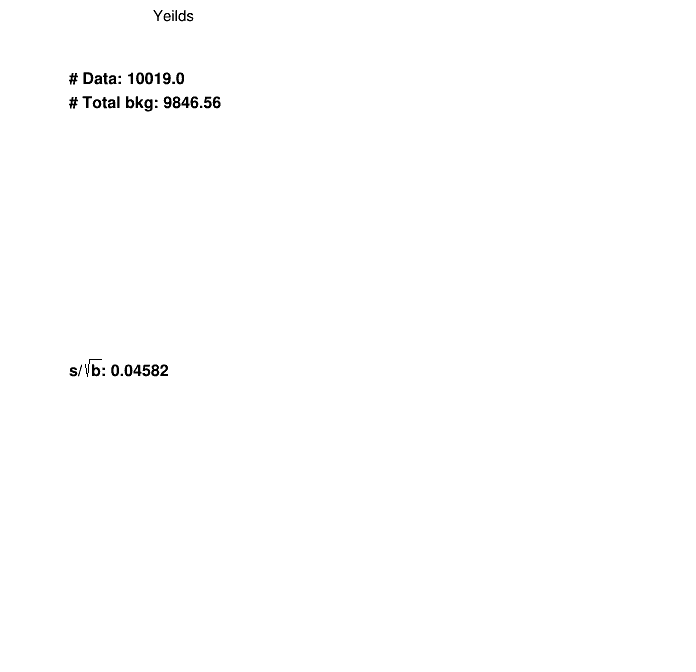

In [27]:
if RUN_SIDEBAND_PT:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [14, 0, 660, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
        "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
        "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
        "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
        "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
        "U_pre": [14, 0, 660, "U [GeV]"],
        "JZB_pre": [14, 80, 660, "JZB"],
        "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
        "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
        "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
        "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "PTSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [28]:
if DUMP_SIDEBAND_PT_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_PT.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# b tag selection

In [29]:
if RUN_BTAG:
    dic_variable={
        "MET_pre": [25, 0, 500, "p_{T}^{miss} [GeV]"],    
#         "PuppiMET_pre": [50, 0, 500, "Puppi p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#         "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"], 
        "nbjetflav_pre": [10, 0, 10, "N bjetflav"], 
#         "nbjet_pre": [10, 0, 10, "N bjet"], 
        "njet_pre": [10, 0, 10, "N jet"], 
#         "njet_l_pre": [9, 1, 10, "N  l jet"],     
#         "njet_c_pre": [9, 1, 10, "N  c jet"],     
#         "njet_b_pre": [9, 1, 10, "N  b jet"],    
#         "btagSF0_pre": [40, 0.9, 1.3, "B SF"],    
    }
    
#     base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>80 and PuppiMET_pre>150 and MT_pre>130"
    base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    dic_df_raw={}
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and njet_pre==1" #temp!
#     query_str=base_line+" and nbjetflav_pre==0" #temp!
    query_str=base_line #temp!

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)  
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
        
    sys_list = ["weight", "wobsf", "wotop"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/Beq0/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/preselv1_"+query_str) 
    
#     hist=HistStack(dic_df_raw, "btagSF0_pre", "genweight_pre", 40, 0.9, 1.3, "B SF")            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/NONBTAG/"+sys_key+"/genweight_pre_preselv1_"+query_str, is_dnn=False) 

        #simply from last instance
        print(hist.get_yeilds())
        hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/pie_"+query_str)
        print(hist.nbin)    
    
#     with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_Beq0.pkl", "wb") as f:
#         pickle.dump(nested_dic_df, f)

# Export variables

In [30]:
if EXPORT_VARIABLE:
    # draw
    # get plot configuration
    dic_variable={
    #     "pt_trail_pre": [8, 40, 300, "p_{T}(l_{trail}) [GeV]"],
    #     "MT2_pre": [8, 0, 160, "M_{T2} [GeV]"],
        "H3PP_pre": [19, 95, 900, "H3PP [GeV]"],     
    }
    sys_src={
        "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre"]
    #     "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre", "topSF_pre"]
    }
    # sys_src=[]
    for key in dic_df_raw:
        if "Zp" in key:
            for variable, r in dic_variable.items():
                hist=HistStack(dic_df_raw, variable, sys_src, "presel", r[0], r[1], r[2], r[3])            
                c1=hist.draw_hist(key, ERA, ERA+"_exportdev"+query_str, True) 
                hist.create_root_file(key, variable, channel)
                hist.export_hist(key, variable, channel, "") 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie()
    print(hist.nbin)


# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file sigeff_em18.pdf has been created


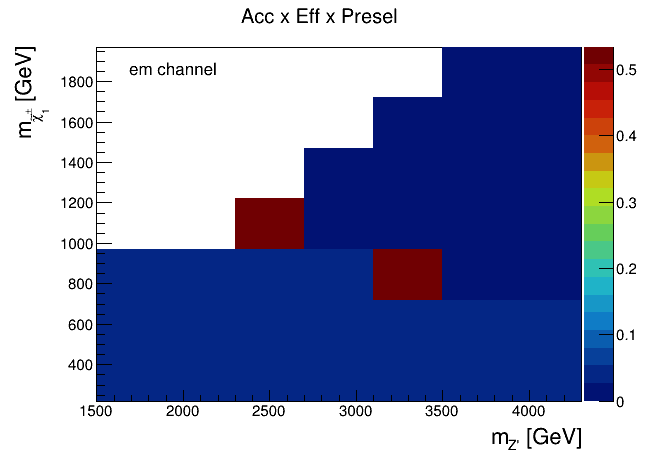

In [31]:
Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# missing bin by hand
h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+"em channel}}")

c1.Draw()
c1.SaveAs("sigeff_"+ERA+".pdf")